### Importa csv do MYSQL

In [26]:
import pandas as pd 
import numpy as np 
from sqlalchemy import create_engine

# Configurações de Conexão (Apenas Leitura)
USER = 'radarrj'
PASSWORD = 't9W58Oe4?mlWIc2tKN'
HOST = '10.11.63.137'
PORT = '3306'
DATABASE = 'radarrj'

engine = create_engine(f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DATABASE}")

print("Baixando dados da tabela radarrj.ato...")
df = pd.read_sql("SELECT * FROM radarrj.ato;", con=engine)

# Tratamento da coluna texto na memória 
if 'texto' in df.columns:
    df['texto'] = (
        df['texto']
        .astype(str)
        .str.replace('|', '-', regex=False)    
        .str.replace('\r', ' ', regex=False)  
        .str.replace('\n', ' ', regex=False)
    )

# Exporta com a barra vertical | como separador de colunas
output_file = "radarrj_ato_limpo.csv"
df.to_csv(output_file, index=False, sep='|', encoding='utf-8-sig')

print(f"Sucesso! Arquivo '{output_file}' gerado sem conflitos de delimitador.")


Baixando dados da tabela radarrj.ato...
Sucesso! Arquivo 'radarrj_ato_limpo.csv' gerado sem conflitos de delimitador.


### Carrega e reordena pela data de publicação

In [92]:
import pandas as pd 
df_ato = pd.read_csv('radarrj_ato_limpo.csv', sep='|')
print(len(df_ato))

90458


C:\Users\daniel.pereira\AppData\Local\Temp\ipykernel_3580\2072986807.py:2: DtypeWarning: Columns (0: id) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ato = pd.read_csv('radarrj_ato_limpo.csv', sep='|')


In [93]:
df_ato['dataPubli'] = pd.to_datetime(df_ato['dataPubli'])
df_ato = df_ato.sort_values(by='dataPubli', ascending=True)
df_ato = df_ato.reset_index(drop=True)
df_ato.tail(1)

,id,idExPaAux,createdAt,dataPubli,parte,secao,subsecao,norma,texto
90457,2745188,3603264,2026-07-01 12:14:38,2026-07-01,Parte I (Poder Executivo),Secretaria de Estado de Saúde,NaN,I - Resolução,SECRETARIA DE ESTADO DE SAÚDE ATO DO SECRE...


### Publicações por semana

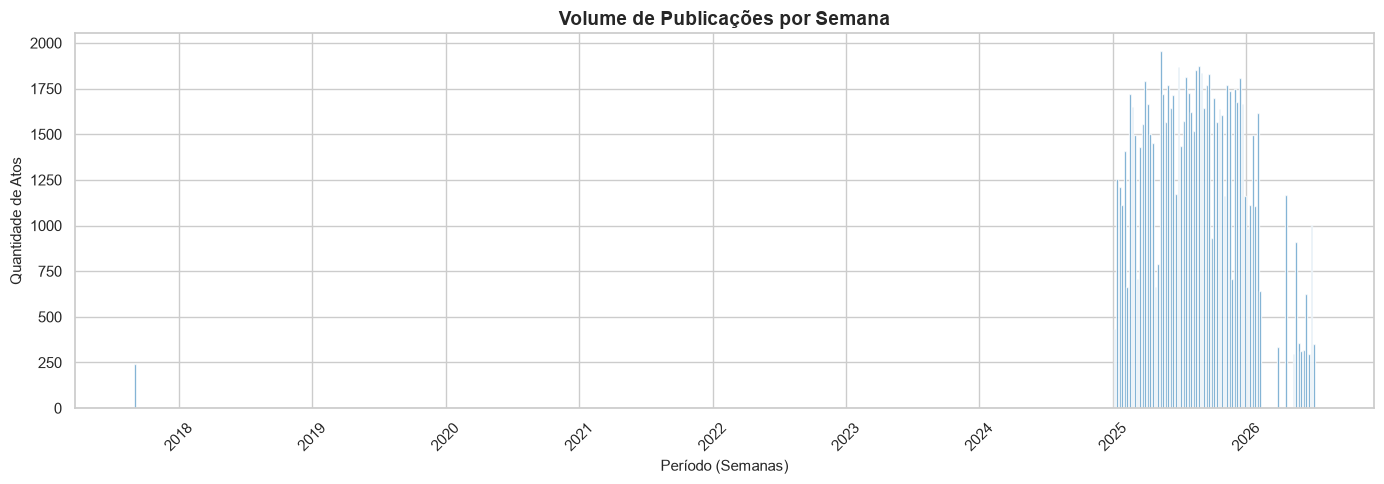

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

publicacoes_semana = df_ato.resample('W', on='dataPubli')['id'].count().reset_index()
publicacoes_semana.columns = ['semana', 'total']

plt.figure(figsize=(14, 5))
plt.bar(publicacoes_semana['semana'], publicacoes_semana['total'], width=5, color='#1f77b4', alpha=0.8)
plt.title('Volume de Publicações por Semana', fontsize=14, fontweight='bold')
plt.xlabel('Período (Semanas)', fontsize=11)
plt.ylabel('Quantidade de Atos', fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Normas

In [95]:
set_normas = set(df_ato['norma'].dropna().unique())
print(set_normas)

{'DOCG - Decreto Normativo', 'IV - Editais: Avisos', 'II - IPALERJ', 'IV - Editais: Concorrências', 'I - Veto Total', 'I - Decisão', 'II - Errata', 'IB - Ato Normativo', 'I - Extrato de Termo', 'V - Demonstrações Financeiras (Balanços)', 'I - Lei Complementar', 'IB - Ato Executivo', 'V - Convocação', 'IB - Despacho', 'II - Ordem do Dia', 'I - Resolução', 'IB - Instrução Normativa', 'IB - Pauta Especial', 'IB - Edital de Citação (Plenário)', 'II - Despachos do Diretor-Geral', 'I - Apostila', 'IV - Editais: Extrato de Instrumento', 'V - Extravio', 'II - Edital', 'II - Projeto de Lei', 'IB - Decisão Monocrática', 'DPGE - Extrato de Termo Aditivo', 'II - Atos do Presidente', 'I - Aviso', 'II - Resoluções', 'V - Aviso de Leilão Extrajudicial', 'V - Impacto Ambiental', 'I - Ordem de Serviço', 'II - Ata', 'V - Relação de Alunos', 'I - Ato', 'I - Ata', 'II - Despachos da Mesa Diretora', 'IB - Edital Administrativo', 'II - Indicações', 'IB - Extrato de Termo de Contrato', 'V - Ata', 'II - Exped

In [96]:
df_ato.columns

Index(['id', 'idExPaAux', 'createdAt', 'dataPubli', 'parte', 'secao',
       'subsecao', 'norma', 'texto'],
      dtype='str')

### Atos com Exonerar ou Nomear

In [98]:
padrao_regex = r'exoner|nomeia|nomea'

df_ato['tem_exo_ou_nom'] = df_ato['texto'].fillna('').str.contains(padrao_regex, case=False, regex=True)

total_atos = len(df_ato)
qtd_encontrados = df_ato['tem_exo_ou_nom'].sum()
porcentagem_total = (qtd_encontrados / total_atos) * 100

print(f"Total de atos na base: {total_atos}")
print(f"Atos com pelo menos um dos termos: {qtd_encontrados} ({porcentagem_total:.2f}%)")

Total de atos na base: 90458
Atos com pelo menos um dos termos: 6101 (6.74%)


### Exoner-

In [99]:
df_ato['exoner'] = df_ato['texto'].fillna('').str.contains('exoner', case=False, regex=True)
df_ato['exonera'] = df_ato['texto'].fillna('').str.contains(r'\bexonera\b', case=False, regex=True)
df_ato['exonero'] = df_ato['texto'].fillna('').str.contains('exonero', case=False, regex=True)
df_ato['exonerou'] = df_ato['texto'].fillna('').str.contains('exonerou', case=False, regex=True)
df_ato['exonerar'] = df_ato['texto'].fillna('').str.contains('exonerar', case=False, regex=True)
df_ato['exoneração'] = df_ato['texto'].fillna('').str.contains('exoneração', case=False, regex=True)
df_ato['exonerado'] = df_ato['texto'].fillna('').str.contains('exonerado', case=False, regex=True)
df_ato['exonerados'] = df_ato['texto'].fillna('').str.contains('exonerados', case=False, regex=True)

variantes_exoner = ['exoner','exonera','exonero','exonerou','exonerar','exoneração','exonerado','exonerados']

for termo in variantes_exoner:
    print(f"Atos com {termo}: {df_ato[termo].sum()}")
df_ato.drop(columns= variantes_exoner, inplace=True)

Atos com exoner: 3550
Atos com exonera: 1796
Atos com exonero: 131
Atos com exonerou: 130
Atos com exonerar: 891
Atos com exoneração: 1189
Atos com exonerado: 189
Atos com exonerados: 44


### Nome-

In [100]:
df_ato['nomea'] = df_ato['texto'].fillna('').str.contains('nomea', case=False, regex=True)
df_ato['nomei'] = df_ato['texto'].fillna('').str.contains('nomei', case=False, regex=True)
df_ato['nomeio'] = df_ato['texto'].fillna('').str.contains('nomeio', case=False, regex=True)
df_ato['nomear'] = df_ato['texto'].fillna('').str.contains(r'\bnomear\b', case=False, regex=True)
df_ato['nomeia'] = df_ato['texto'].fillna('').str.contains('nomeia', case=False, regex=True)
df_ato['nomeiam'] = df_ato['texto'].fillna('').str.contains('nomeiam', case=False, regex=True)
df_ato['nomeado'] = df_ato['texto'].fillna('').str.contains('nomeado', case=False, regex=True)

variantes_nome = ['nomea','nomei','nomeio','nomeia','nomeiam','nomear','nomeado']

for termo in variantes_nome:
    print(f"Atos com {termo}: {df_ato[termo].sum()}")
df_ato.drop(columns= variantes_nome, inplace=True)

Atos com nomea: 2544
Atos com nomei: 1918
Atos com nomeio: 25
Atos com nomeia: 1914
Atos com nomeiam: 1
Atos com nomear: 1101
Atos com nomeado: 429


### Função pegar_nome

In [107]:
import re

def pegar_nome(texto, termo):
    if not isinstance(texto, str):
        return None

    padrao = rf"(?i:\b(?:{termo})\b)(?:(?![A-ZÁÀÉÍÓÚÂÊÔÃÕÇ']{{3,}}).)*?\b([A-ZÁÀÉÍÓÚÂÊÔÃÕÇ']{{3,}}(?:\s+(?:[A-ZÁÀÉÍÓÚÂÊÔÃÕÇ']{{1,}}|DA|DO|DE|DOS|DAS|E))+)\b"
    
    resultados = re.findall(padrao, texto)
    
    if resultados:
        return ", ".join(resultados) 
        
    return None

# Testes

texto_teste_1 = "O órgão EXONERA CARLOS ALBERTO D'ALMEIDA e também exonerar .MARIA PEREIRA. COUTO."
print("Teste 1:", pegar_nome(texto_teste_1, termo='exonera|exonerar'))


texto_teste_2 = "Fica decidido que NOMEIA JOAO do cargo."
print("Teste 2:", pegar_nome(texto_teste_2, termo='nomeia'))


texto_teste_3 = "Fica decidido que NOMEIA JOAO SILVA do cargo."
print("Teste 3:", pegar_nome(texto_teste_3, termo='nomeia'))


Teste 1: CARLOS ALBERTO D'ALMEIDA, MARIA PEREIRA
Teste 2: None
Teste 3: JOAO SILVA


### Exonerados

In [103]:
df_ato['exonera_exonerar'] = df_ato['texto'].fillna('').str.contains(r'\bexonera|exonerar\b', case=False, regex=True)
df_ato.loc[df_ato['exonera_exonerar'], 'Exonerados'] = df_ato.loc[df_ato['exonera_exonerar'], 'texto'].apply(pegar_nome, termo='exonera|exonerar')
df_ato['Exonerados'].notna().sum()

np.int64(2276)

In [16]:
linhas_com_exonerados = df_ato[df_ato['Exonerados'].notna()]

# Salvar nomes em CSV
linhas_com_exonerados[['id', 'dataPubli', 'Exonerados']].to_csv(
    'nomes_exonerados.csv',
    index=False
)

### Nomeados

In [104]:
df_ato['nomear_nomeia'] = df_ato['texto'].fillna('').str.contains(r'\bnomear|nomeia\b', case=False, regex=True)
df_ato.loc[df_ato['nomear_nomeia'], 'Nomeados'] = df_ato.loc[df_ato['nomear_nomeia'], 'texto'].apply(pegar_nome, termo='nomear|nomeia')
df_ato['Nomeados'].notna().sum()

np.int64(2597)

In [10]:
linhas_com_nomeados = df_ato[df_ato['Nomeados'].notna()]

# Salvar nomes em CSV
linhas_com_nomeados[['id', 'dataPubli', 'Nomeados']].to_csv(
    'nomes_nomeados.csv',
    index=False
)

## Casos a ver: 

PM RG

nova função

### Função PM RG


#### Exonerados

In [136]:
df_ato['tem_PM_RG_E'] = df_ato['Exonerados'].fillna('').str.contains(r'\bRG\b', case=False, regex=True)

df_ato.loc[df_ato['tem_PM_RG_E'], 'Nome_PM_RG_E'] = df_ato.loc[df_ato['tem_PM_RG_E'], 'texto'].apply(pegar_nome, termo='RG')

print(df_ato['Nome_PM_RG_E'].notnull().sum())
print(df_ato['tem_PM_RG_E'].sum())

18
18


In [128]:
padrao_rg = r"(?i)\b(?:CEL\s+)?(?:PM\s+)?RG\b\s*\d*|\b[A-ZÁÀÉÍÓÚÂÊÔÃÕÇ']{3,}(?:\s+(?:[A-ZÁÀÉÍÓÚÂÊÔÃÕÇ']{1,}|DA|DO|DE|DOS|DAS|E))*\s+(?:CEL\s+)?(?:PM\s+)?RG\b\s*\d*"

df_ato['Exonerados_Limpos'] = df_ato['Exonerados']
df_ato['Exonerados_Limpo'] = df_ato['Exonerados_Limpos'].fillna('').str.replace(padrao_rg, '', regex=True)

df_ato['Exonerados_Limpo'] = (
    df_ato['Exonerados_Limpo']
    .str.replace(r'\s*,\s*,', ',', regex=True)  
    .str.strip(' ,')                         
)


def somar_nomes(row):
    exonerado_original = row['Exonerados_Limpo']
    nome_extraido = row['Nome_PM_RG_E']
    
    # Se existe nome extraído válido (notna)
    if pd.notna(nome_extraido) and str(nome_extraido).strip() != '':
        # Se a coluna original não estava vazia, junta com vírgula
        if exonerado_original:
            return f"{exonerado_original}, {nome_extraido}"
        return str(nome_extraido)
    
    return exonerado_original

# Aplica a junção linha a linha
df_ato['Exonerados_Limpos'] = df_ato.apply(somar_nomes, axis=1)

# Remove a coluna temporária de limpeza
df_ato.drop(columns=['Exonerados_Limpo'], inplace=True)

In [138]:
linhas_com_exonerados_PM_RG = df_ato[df_ato['Exonerados_Limpos'].notna()]

# Salvar nomes em CSV
linhas_com_exonerados_PM_RG[['id', 'dataPubli', 'Exonerados_Limpos']].to_csv(
    'nomes_exonerados_limpo.csv',
    index=False
)

#### Nomeados

In [73]:
df_ato['tem_PM_RG_N'] = df_ato['Nomeados'].fillna('').str.contains(r'\bPM\b', case=False, regex=True)

df_ato.loc[df_ato['tem_PM_RG_N'], 'Nome_PM_RG_N'] = df_ato.loc[df_ato['tem_PM_RG_N'], 'texto'].apply(pegar_nome, termo='PM')

print(df_ato['Nome_PM_RG_N'].notnull().sum())
print(df_ato['tem_PM_RG_N'].sum())

71
71
